# BÀI 1: PHÂN TÍCH DỮ LIỆU DIABETES

Họ tên: Đặng Văn Chung

Mã sinh viên: 24174800194

Các đặc trưng được chọn: bmi, bp, s5.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)

df = diabetes.data.copy()
df["target"] = diabetes.target.copy()

features = ["bmi", "bp", "s5"]

print("Kích thước dữ liệu:", df.shape)
display(df[features + ["target"]].head())

Kích thước dữ liệu: (442, 11)


,bmi,bp,s5,target
0,0.061696,0.021872,0.019907,151.0
1,-0.051474,-0.026328,-0.068332,75.0
2,0.044451,-0.005670,0.002861,141.0
3,-0.011595,-0.036656,0.022688,206.0
4,-0.036385,0.021872,-0.031988,135.0


In [ ]:
print("Kiểu dữ liệu:")
print(df[features + ["target"]].dtypes)

print("\nSố giá trị thiếu:")
print(df[features + ["target"]].isnull().sum())

print("\nThống kê mô tả:")
display(df[features + ["target"]].describe().T)

Kiểu dữ liệu:
bmi       float64
bp        float64
s5        float64
target    float64
dtype: object

Số giá trị thiếu:
bmi       0
bp        0
s5        0
target    0
dtype: int64

Thống kê mô tả:


,count,mean,std,min,25%,50%,75%,max
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
target,442.0,1.521335e+02,77.093005,25.000000,87.000000,140.500000,211.500000,346.000000


Tạo bảng phân bố bằng histogram: chia giá trị thành các khoảng, đếm số mẫu trong mỗi khoảng rồi vẽ cột.

| Chỉ số | Ý nghĩa đơn giản | Ví dụ ở hàng `target` |
|---|---|---|
| `count` | Số giá trị không bị thiếu | Có **442** giá trị |
| `mean` | Giá trị trung bình | Khoảng **152.13** |
| `std` | Độ lệch chuẩn: mức độ các giá trị phân tán quanh trung bình | Khoảng **77.09** |
| `min` | Giá trị nhỏ nhất | **25** |
| `25%` | Mốc phân vị 25%, gọi là **Q1** | **87** |
| `50%` | Giá trị ở giữa dữ liệu, gọi là **trung vị** | **140.5** |
| `75%` | Mốc phân vị 75%, gọi là **Q3** | **211.5** |
| `max` | Giá trị lớn nhất | **346** |

Kết quả: bmi lệch phải rõ rệt, bp và s5 lệch phải nhẹ hơn.

### Phân tích phân phối của bmi, bp và s5

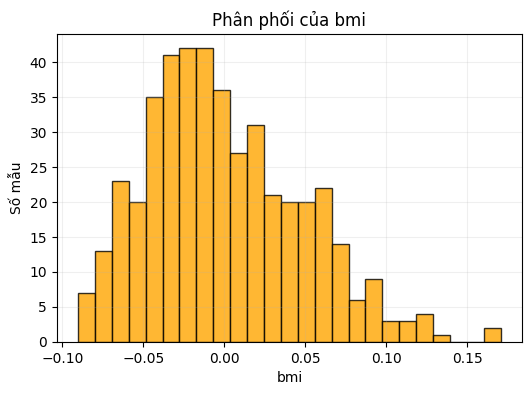

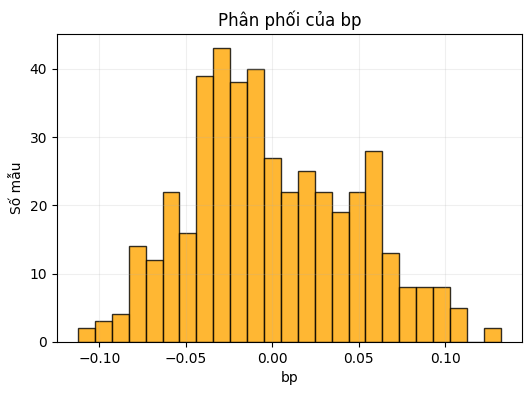

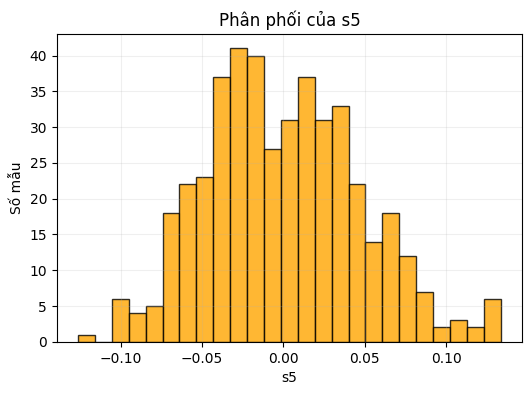

In [ ]:
for col in features:
    plt.figure(figsize=(6, 4))
    plt.hist(
        df[col],
        bins=25,
        edgecolor="black",
        color="orange",
        alpha=0.8
    )
    plt.title(f"Phân phối của {col}")
    plt.xlabel(col)
    plt.ylabel("Số mẫu")
    plt.grid(alpha=0.2)
    plt.show()

In [ ]:
outlier_summary = []

for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append([
        col, int(n_outliers), lower, upper
    ])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "Đặc trưng",
        "Số ngoại lệ",
        "Ngưỡng dưới",
        "Ngưỡng trên"
    ]
)

display(outlier_df)

,Đặc trưng,Số ngoại lệ,Ngưỡng dưới,Ngưỡng trên
0,bmi,3,-0.132445,0.129464
1,bp,0,-0.145106,0.144094
2,s5,4,-0.131762,0.130949


### Phát hiện ngoại lệ bằng phương pháp IQR

Phương pháp: dùng khoảng chứa 50% dữ liệu ở giữa để xác định các giá trị quá xa.

Cách làm với từng cột:
1. Tính Q1: mốc phân vị 25%.
2. Tính Q3: mốc phân vị 75%.
3. Tính IQR = Q3 - Q1.
4. Tạo hai ngưỡng:
   - Ngưỡng dưới: Q1 - 1.5 × IQR.
   - Ngưỡng trên: Q3 + 1.5 × IQR.
5. Đếm giá trị nằm ngoài hai ngưỡng.


Kết quả: bmi có 3 ngoại lệ, bp có 0, s5 có 4.

### Phân tích tương quan với target

In [ ]:
corr = df[features + ["target"]].corr()

target_corr = corr["target"].drop("target")

display(target_corr.to_frame("Tương quan với target"))

,Tương quan với target
bmi,0.586450
bp,0.441482
s5,0.565883


Bằng công thức Pearson, ta lấy luần lược các giá trị như bmi, bp và s5 sau đó so sánh lần lượt với target để lấy thành các cặp riêng biệt, từ các cặp này ta tính trung bình của từng cột sau đó, với mỗi người, ta xem:

  - bmi của người đó cao hơn hay thấp hơn trung bình bmi?

  - target của người đó cao hơn hay thấp hơn trung bình target?

Hai độ chênh lệch được nhân với nhau:
  | Trường hợp | Tích hai độ chênh lệch |
|---|---|
| Cả hai cùng cao hơn trung bình | Dương |
| Cả hai cùng thấp hơn trung bình | Dương |
| Một cao hơn, một thấp hơn trung bình | Âm |

Nếu các tích dương chiếm ưu thế, hệ số tương quan sẽ dương: hai cột có xu hướng tăng cùng nhau.
  - Công thức tính

  Gọi \(x\) là bmi, \(y\) là target:


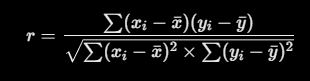


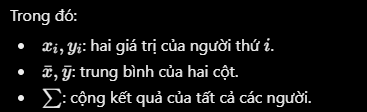

Tử số đo việc hai cột thay đổi cùng nhau. Mẫu số điều chỉnh theo mức phân tán của hai cột, đưa kết quả về khoảng từ −1 đến 1.

### Biểu đồ phân tán giữa các đặc trưng và target

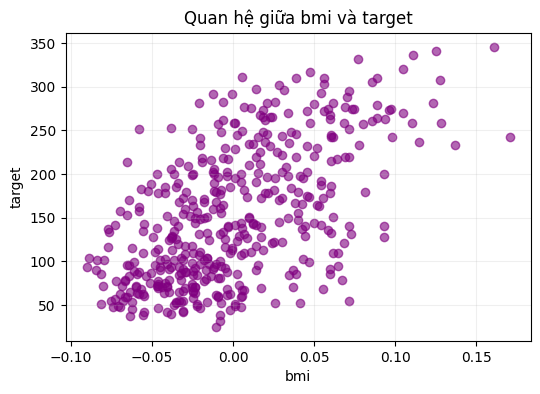

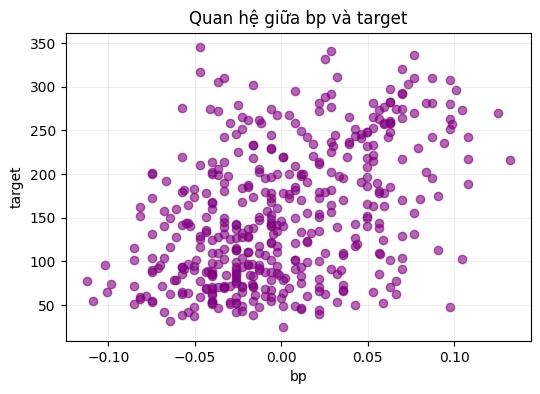

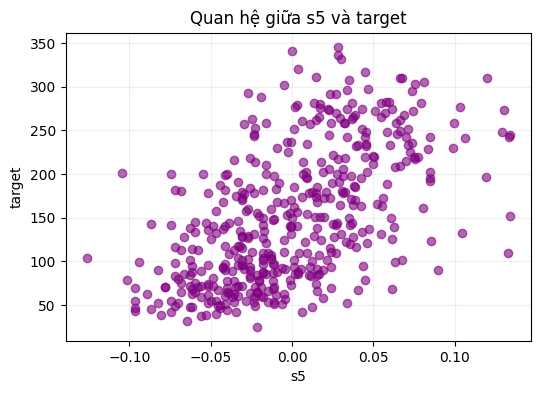

In [ ]:
for col in features:
    plt.figure(figsize=(6, 4))
    plt.scatter(
        df[col],
        df["target"],
        color="purple",
        alpha=0.6
    )
    plt.title(f"Quan hệ giữa {col} và target")
    plt.xlabel(col)
    plt.ylabel("target")
    plt.grid(alpha=0.2)
    plt.show()

| Đặc trưng | Phân phối | Ngoại lệ theo IQR | Tương quan với `target` |
|---|---|---:|---:|
| `bmi` | Lệch phải khá rõ | 3 | 0.586450 |
| `bp` | Lệch phải nhẹ | 0 | 0.441482 |
| `s5` | Lệch phải nhẹ | 4 | 0.565883 |

| Đặc trưng | Nhận xét từ scatter plot |
|---|---|
| `bmi` | Các điểm có xu hướng đi lên: `bmi` tăng thì `target` thường tăng. Tuy nhiên, ở cùng một mức `bmi`, `target` vẫn khác nhau khá nhiều |
| `bp` | Có xu hướng tăng nhưng các điểm phân tán rộng, quan hệ tuyến tính kém rõ hơn `bmi` và `s5` |
| `s5` | Các điểm có xu hướng đi lên tương đối rõ, phù hợp với tương quan dương khoảng 0.5659. Dữ liệu vẫn phân tán đáng kể |

# BÀI 2: SO SÁNH MÔ HÌNH VỚI CÁC BỘ ĐẶC TRƯNG KHÁC NHAU

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_all = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y,
    test_size=0.2,
    random_state=42
)

print("Kích thước tập train:", X_train.shape)
print("Kích thước tập test:", X_test.shape)

Kích thước tập train: (353, 10)
Kích thước tập test: (89, 10)


In [ ]:
train_corr = X_train.corrwith(y_train)

top5 = (
    train_corr.abs()
    .sort_values(ascending=False)
    .head(5)
    .index.tolist()
)

feature_sets = {
    "bmi": ["bmi"],
    "bmi + bp": ["bmi", "bp"],
    "Top 5": top5,
    "Toàn bộ 10": X_all.columns.tolist()
}

print("Top 5 đặc trưng:", top5)

for name, cols in feature_sets.items():
    print(name, ":", cols)

Top 5 đặc trưng: ['bmi', 's5', 'bp', 's4', 's6']
bmi : ['bmi']
bmi + bp : ['bmi', 'bp']
Top 5 : ['bmi', 's5', 'bp', 's4', 's6']
Toàn bộ 10 : ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


### Huấn luyện và đánh giá các mô hình Linear Regression

In [ ]:
results_bai2 = []

for name, cols in feature_sets.items():
    model = LinearRegression()

    model.fit(X_train[cols], y_train)

    y_pred = model.predict(X_test[cols])

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results_bai2.append({
        "Bộ đặc trưng": name,
        "Số đặc trưng": len(cols),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

comparison_bai2 = pd.DataFrame(results_bai2)

display(comparison_bai2.round(4))

,Bộ đặc trưng,Số đặc trưng,MAE,RMSE,R2
0,bmi,1,52.2600,63.7325,0.2334
1,bmi + bp,2,50.0441,61.1597,0.2940
2,Top 5,5,44.3288,53.8493,0.4527
3,Toàn bộ 10,10,42.7941,53.8534,0.4526


### Kết luận bài 2

Kết quả cho thấy bộ đặc trưng đầu vào ảnh hưởng đến hiệu quả của mô hình Linear Regression. Khi bổ sung `bp` vào `bmi`, MAE và RMSE giảm, đồng thời R² tăng. Sử dụng top 5 đặc trưng tiếp tục cải thiện rõ khả năng dự đoán so với hai bộ ít đặc trưng hơn.

Mô hình sử dụng toàn bộ 10 đặc trưng đạt MAE thấp nhất là 42.7941. Bộ top 5 đạt RMSE thấp nhất là 53.8493 và R² cao nhất là 0.4527, nhưng hai chỉ số này gần như tương đương với mô hình sử dụng toàn bộ 10 đặc trưng.

Trên tập test hiện tại, bộ top 5 cho kết quả gần tương đương bộ 10 theo RMSE và R², trong khi bộ 10 có lợi thế về MAE. Vì vậy, cần xem xét đồng thời các chỉ số khi so sánh mô hình; tăng số đặc trưng không bảo đảm mọi chỉ số đều tốt hơn.

# BÀI 3: SO SÁNH CÁC THUẬT TOÁN HỒI QUY

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

print("Đã nhập thư viện cho bài 3")

Đã nhập thư viện cho bài 3


In [ ]:
models_bai3 = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    ),

    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=100, epsilon=1.0)
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

print("Số mô hình:", len(models_bai3))

for name in models_bai3:
    print(name)

Số mô hình: 5
Linear Regression
Ridge Regression
Decision Tree
SVR
Gradient Boosting


In [ ]:
results_bai3 = []

for name, model in models_bai3.items():
    # Huấn luyện mô hình
    model.fit(X_train, y_train)

    # Dự đoán trên tập huấn luyện và tập kiểm tra
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Tính các chỉ số đánh giá
    results_bai3.append({
        "Mô hình": name,
        "MAE": mean_absolute_error(y_test, y_pred_test),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, y_pred_test)
        ),
        "R2 Test": r2_score(y_test, y_pred_test),
        "R2 Train": r2_score(y_train, y_pred_train)
    })

comparison_bai3 = pd.DataFrame(results_bai3)

comparison_bai3 = comparison_bai3.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(comparison_bai3.round(4))

,Mô hình,MAE,RMSE,R2 Test,R2 Train
0,SVR,39.4924,51.0560,0.5080,0.6684
1,Ridge Regression,42.8120,53.7775,0.4541,0.5276
2,Gradient Boosting,44.6033,53.8371,0.4529,0.8359
3,Linear Regression,42.7941,53.8534,0.4526,0.5279
4,Decision Tree,47.0454,59.7408,0.3264,0.5846


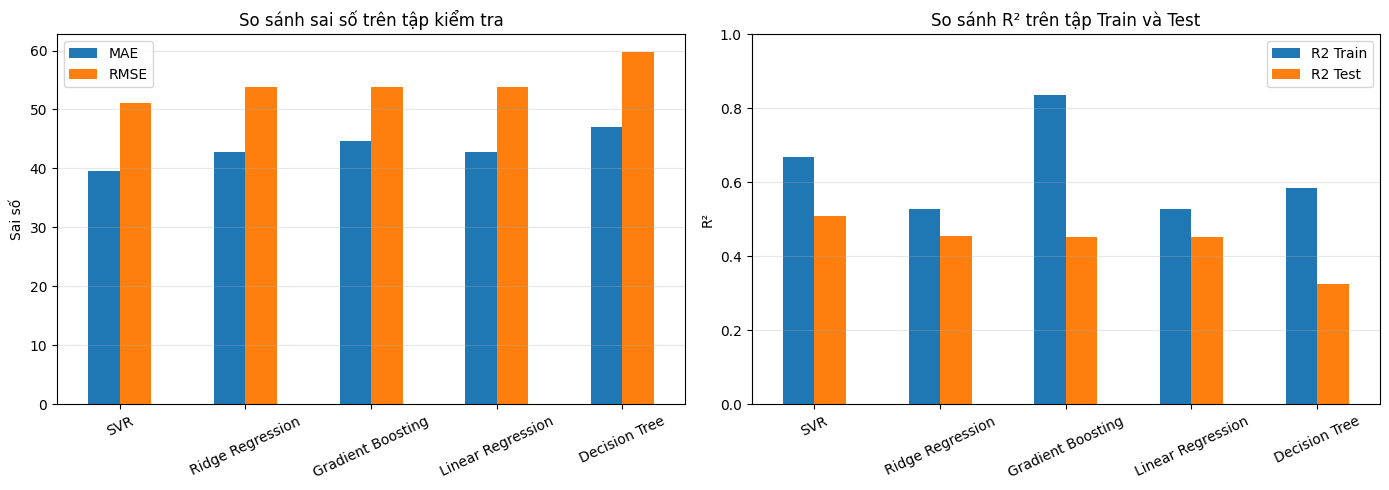

In [ ]:
plot_data = comparison_bai3.set_index("Mô hình")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_data[["MAE", "RMSE"]].plot(
    kind="bar",
    ax=axes[0],
    rot=25
)
axes[0].set_title("So sánh sai số trên tập kiểm tra")
axes[0].set_ylabel("Sai số")
axes[0].set_xlabel("")
axes[0].grid(axis="y", alpha=0.3)

plot_data[["R2 Train", "R2 Test"]].plot(
    kind="bar",
    ax=axes[1],
    rot=25
)
axes[1].set_title("So sánh R² trên tập Train và Test")
axes[1].set_ylabel("R²")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 1)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Kết luận bài 3

Trong năm mô hình đã thử, SVR cho kết quả tốt nhất trên tập kiểm tra với MAE = 39.4924, RMSE = 51.0560 và R² = 0.5080. Ridge Regression và Linear Regression có hiệu quả gần tương đương.

Gradient Boosting có R² Train = 0.8359 nhưng R² Test = 0.4529, cho thấy dấu hiệu học quá khớp. Decision Tree có kết quả thấp nhất trong lần thử này.

Với cách chia dữ liệu và các tham số đã sử dụng, SVR là mô hình cho dự đoán tốt nhất. Kết quả này chưa khẳng định SVR luôn tốt nhất trên các cách chia dữ liệu hoặc cấu hình khác.